# 02 - Train and evaluate a Sentinel-1 land cover model

A U-Net (ResNet-34 encoder, trained from scratch) reads two radar bands (VV, VH) and labels every pixel with one of 7 classes.

Two variants differ in one thing only, set by `MONTHLY_ONLY` below:
- **A, monthly only** (`MONTHLY_ONLY = True`): pixels whose label was filled from the yearly map are ignored in training.
- **B, hybrid** (`MONTHLY_ONLY = False`): filled pixels are used, with a smaller loss weight.

Run the notebook once per variant. Both are scored on the same pixels, real monthly labels only, so the comparison is fair.

## 1. Settings

In [1]:
MONTHLY_ONLY = False   # True = variant A (monthly labels only), False = variant B (hybrid labels)
FILLED_WEIGHT = 0.3    # loss weight of pixels whose label was filled from the yearly map (hybrid run only)
EPOCHS = 30
BATCH = 16
LR = 1e-3
SMOKE = False          # True = tiny quick run just to check that everything works
NAME = "monthly_only" if MONTHLY_ONLY else "hybrid"

## 2. Data

`LULCDataset` (in `lulc.py`) cuts 256x256 windows and gives, for each one: scaled radar `x`, the 7-class label `y`
(255 = ignore), the label's confidence, and `filled` (True where the label came from the yearly map).

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from lulc import CLASSES, IGNORE, LULCDataset

C = len(CLASSES)
cuda = torch.cuda.is_available()
device = "cuda" if cuda else "cpu"
torch.backends.cudnn.benchmark = True
print("device:", device, torch.cuda.get_device_name(0) if cuda else "")

train_ds, val_ds, test_ds = (LULCDataset(r) for r in ("train", "val", "test"))
if SMOKE:
    EPOCHS = 1
    for ds in (train_ds, val_ds, test_ds):
        ds.items = ds.items[::max(1, len(ds.items) // 64)][:64]   # spread over all sites and months
print({"train": len(train_ds), "val": len(val_ds), "test": len(test_ds)}, "patches")

workers = 0   # the container has almost no shared memory (/dev/shm), so no worker processes
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=workers, drop_last=True)

/home/jovyan/vault/Deep_learning_project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda NVIDIA RTX A6000
{'train': 5292, 'val': 2352, 'test': 1764} patches


## 3. Class weights

Rare classes (bare, water) would be drowned out by built and trees. Each class is weighted by the inverse square root of
how common it is in the training data, which is a milder correction than full inverse frequency.

In [3]:
lab = np.concatenate([l.ravel() for l in train_ds.label])
freq = np.bincount(lab, minlength=256)[:C] / (lab != IGNORE).sum()
class_w = 1 / np.sqrt(np.maximum(freq, 1e-6))
class_w = torch.tensor(class_w / class_w.mean(), dtype=torch.float32).to(device)
print({c: round(float(w), 2) for c, w in zip(CLASSES, class_w.cpu())})

{'water': 1.18, 'trees': 0.72, 'low_vegetation': 0.86, 'flooded_vegetation': 1.13, 'crops': 0.81, 'built': 0.46, 'bare': 1.83}


## 4. Model, loss, optimiser

- **Model:** `smp.Unet` with a ResNet-34 encoder and no pretrained weights. 2 input channels, 7 output classes.
- **Loss:** per-pixel cross-entropy with class weights. Ignored pixels contribute nothing. In the hybrid run, filled pixels are multiplied by `FILLED_WEIGHT`.
- **Learning rate:** starts at `LR` and shrinks smoothly to zero over training (cosine schedule).
- **Confidence** is not used in this first iteration.

In [4]:
model = smp.Unet("resnet34", encoder_weights=None, in_channels=2, classes=C).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_loader))
ce = nn.CrossEntropyLoss(weight=class_w, ignore_index=IGNORE, reduction="none")


def batch_loss(logits, y, filled):
    """Weighted cross-entropy averaged over the pixels that have a usable label."""
    if MONTHLY_ONLY:
        y = y.masked_fill(filled, IGNORE)            # variant A: filled pixels give no feedback
        w = torch.ones(y.shape, device=y.device)
    else:
        w = 1.0 - (1.0 - FILLED_WEIGHT) * filled.float()   # variant B: filled pixels count for less
    valid = (y != IGNORE).float() * w
    return (ce(logits, y) * w).sum() / valid.sum().clamp(min=1)


def augment(x, y, filled):
    """Random 90-degree rotation and flip, the same for the whole batch (radar has no 'up')."""
    k = np.random.randint(4)
    x, y, filled = (torch.rot90(t, k, (-2, -1)) for t in (x, y, filled))
    if np.random.rand() < 0.5:
        x, y, filled = (torch.flip(t, (-1,)) for t in (x, y, filled))
    return x, y, filled

## 5. Scoring

Everything is scored on **real monthly labels only** (pixels with a label that is not filled), whichever variant was trained.
A confusion matrix counts, for every true class, which class the model predicted. All the scores come from it:
overall accuracy (OA), IoU and F1 per class, and mean IoU (mIoU) over the classes that appear.

In [5]:
@torch.no_grad()
def confusion(ds):
    """Returns the confusion matrix over the whole set, and one per month (12 entries)."""
    model.eval()
    total = np.zeros((C, C), np.int64)
    per_month = {m: np.zeros((C, C), np.int64) for m in range(1, 13)}
    months = [ds.month[k] for k, _, _ in ds.items]
    seen = 0
    for x, y, _, filled in DataLoader(ds, batch_size=BATCH * 2):
        with torch.autocast(device_type=device, dtype=torch.bfloat16, enabled=cuda):
            pred = model(x.to(device)).argmax(1).cpu()
        for i in range(len(y)):
            keep = (y[i] != IGNORE) & ~filled[i]
            cm = np.bincount((y[i][keep] * C + pred[i][keep]).numpy(), minlength=C * C).reshape(C, C)
            total += cm
            per_month[months[seen + i]] += cm
        seen += len(y)
    return total, per_month


def scores(cm):
    tp = np.diag(cm).astype(float)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    iou = tp / np.maximum(tp + fp + fn, 1)
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    present = cm.sum(1) > 0
    return {"oa": tp.sum() / max(cm.sum(), 1), "miou": iou[present].mean() if present.any() else 0.0,
            "iou": iou, "f1": f1, "pixels": int(cm.sum())}


# self-check of the scoring: a perfect prediction scores 1, and a fully wrong one scores 0
_cm = np.diag(np.arange(1, C + 1) * 10)
assert scores(_cm)["oa"] == 1 and abs(scores(_cm)["miou"] - 1) < 1e-9
_cm = np.roll(_cm, 1, axis=1)
assert scores(_cm)["oa"] == 0

## 6. Train

In [6]:
os.makedirs("weights", exist_ok=True)
history = {"loss": [], "val_oa": [], "val_miou": [], "lr": []}
best = -1.0

for epoch in range(EPOCHS):
    model.train()
    running = []
    for x, y, _, filled in train_loader:
        x, y, filled = augment(x.to(device), y.to(device), filled.to(device))
        with torch.autocast(device_type=device, dtype=torch.bfloat16, enabled=cuda):
            logits = model(x)
        loss = batch_loss(logits.float(), y, filled)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()
        running.append(loss.item())
    s = scores(confusion(val_ds)[0])
    history["loss"].append(float(np.mean(running)))
    history["val_oa"].append(float(s["oa"]))
    history["val_miou"].append(float(s["miou"]))
    history["lr"].append(opt.param_groups[0]["lr"])
    if s["miou"] > best:                      # keep the weights that do best on validation sites
        best = s["miou"]
        torch.save(model.state_dict(), f"weights/{NAME}.pt")
    print(f"epoch {epoch + 1:2d}/{EPOCHS}  loss {history['loss'][-1]:.3f}  val OA {s['oa']:.3f}  val mIoU {s['miou']:.3f}")

epoch  1/30  loss 0.982  val OA 0.406  val mIoU 0.186
epoch  2/30  loss 0.907  val OA 0.232  val mIoU 0.128
epoch  3/30  loss 0.859  val OA 0.277  val mIoU 0.144
epoch  4/30  loss 0.837  val OA 0.490  val mIoU 0.236
epoch  5/30  loss 0.810  val OA 0.305  val mIoU 0.169
epoch  6/30  loss 0.791  val OA 0.510  val mIoU 0.241
epoch  7/30  loss 0.767  val OA 0.519  val mIoU 0.249
epoch  8/30  loss 0.762  val OA 0.372  val mIoU 0.143
epoch  9/30  loss 0.745  val OA 0.527  val mIoU 0.256
epoch 10/30  loss 0.740  val OA 0.478  val mIoU 0.217
epoch 11/30  loss 0.717  val OA 0.499  val mIoU 0.245
epoch 12/30  loss 0.710  val OA 0.487  val mIoU 0.252
epoch 13/30  loss 0.700  val OA 0.350  val mIoU 0.143
epoch 14/30  loss 0.693  val OA 0.395  val mIoU 0.179
epoch 15/30  loss 0.683  val OA 0.477  val mIoU 0.241
epoch 16/30  loss 0.672  val OA 0.394  val mIoU 0.199
epoch 17/30  loss 0.669  val OA 0.223  val mIoU 0.137
epoch 18/30  loss 0.663  val OA 0.465  val mIoU 0.245
epoch 19/30  loss 0.655  val

## 7. Training curves

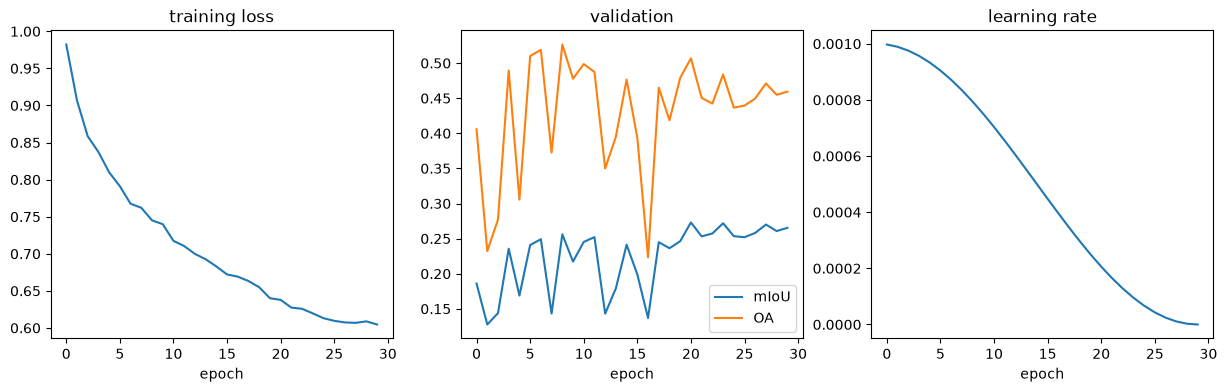

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(history["loss"]); ax[0].set_title("training loss")
ax[1].plot(history["val_miou"], label="mIoU"); ax[1].plot(history["val_oa"], label="OA"); ax[1].legend(); ax[1].set_title("validation")
ax[2].plot(history["lr"]); ax[2].set_title("learning rate")
for a in ax: a.set_xlabel("epoch")
plt.show()

## 8. Test scores (test sites, real monthly labels only)

The test sites have not been used for training or for choosing weights. Scores are by class and by month. Months with few labelled pixels (the rainy season) rest on thin data, so the number of pixels is printed too.

In [8]:
model.load_state_dict(torch.load(f"weights/{NAME}.pt", map_location=device))
total, per_month = confusion(test_ds)
t = scores(total)
print(f"[{NAME}] test OA {t['oa']:.3f}  mIoU {t['miou']:.3f}  over {t['pixels']:,} labelled pixels\n")
print(f"{'class':20s}{'IoU':>7s}{'F1':>7s}{'pixels':>12s}")
for i, c in enumerate(CLASSES):
    print(f"{c:20s}{t['iou'][i]:7.3f}{t['f1'][i]:7.3f}{int(total[i].sum()):12,d}")
print(f"\n{'month':>5s}{'OA':>7s}{'mIoU':>7s}{'pixels':>12s}")
months = {}
for m, cm in per_month.items():
    s = scores(cm)
    months[m] = {"oa": float(s["oa"]), "miou": float(s["miou"]), "pixels": s["pixels"]}
    print(f"{m:5d}{s['oa']:7.3f}{s['miou']:7.3f}{s['pixels']:12,d}")
json.dump({"name": NAME, "oa": float(t["oa"]), "miou": float(t["miou"]), "iou": t["iou"].tolist(), "f1": t["f1"].tolist(),
           "months": months, "history": history}, open(f"results_{NAME}.json", "w"))

[hybrid] test OA 0.583  mIoU 0.232  over 70,010,439 labelled pixels

class                   IoU     F1      pixels
water                 0.065  0.122     759,350
trees                 0.204  0.339   5,500,991
low_vegetation        0.323  0.488  15,480,003
flooded_vegetation    0.035  0.068      83,006
crops                 0.174  0.297   8,511,496
built                 0.781  0.877  33,015,911
bare                  0.039  0.075   6,659,682

month     OA   mIoU      pixels
    1  0.468  0.184   9,633,300
    2  0.484  0.197   9,633,772
    3  0.508  0.213   9,633,772
    4  0.585  0.240   9,633,792
    5  0.651  0.303   6,422,528
    6  0.827  0.345     932,500
    7  0.000  0.000           0
    8  0.000  0.000           0
    9  0.181  0.104     255,741
   10  0.795  0.341   4,598,578
   11  0.686  0.326   9,633,600
   12  0.607  0.249   9,632,856


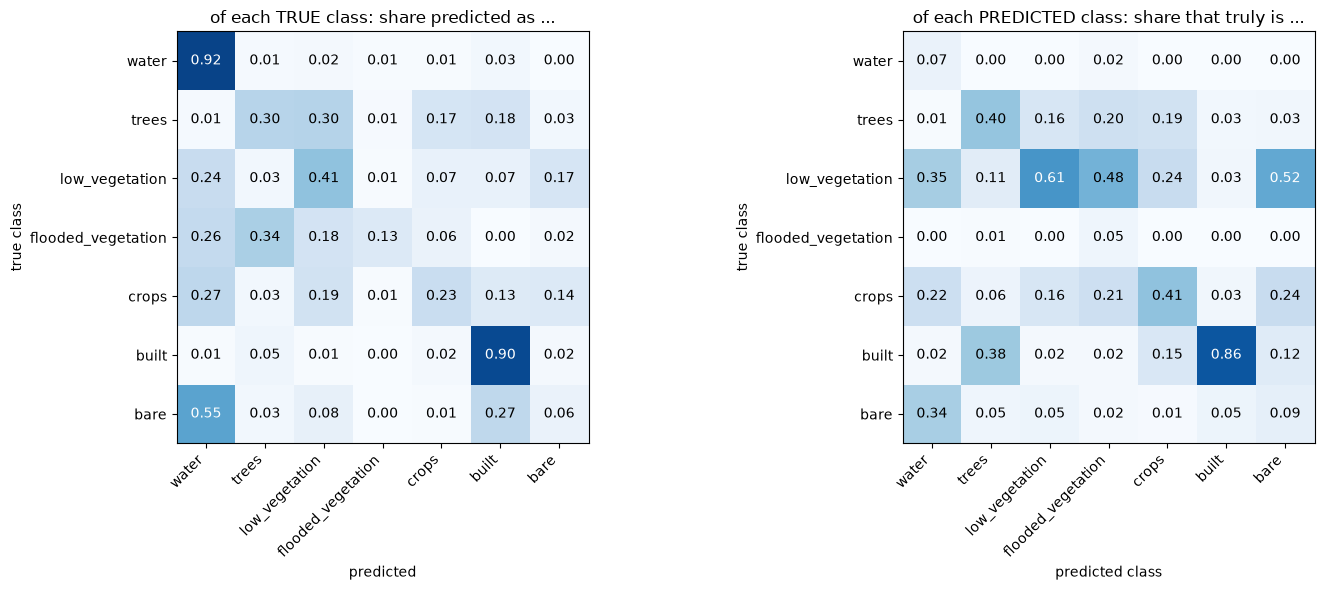

In [9]:
cm = total.astype(float)
by_true = cm / np.maximum(cm.sum(1, keepdims=True), 1)    # each row sums to 1
by_pred = cm / np.maximum(cm.sum(0, keepdims=True), 1)    # each column sums to 1

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, m, title in ((ax[0], by_true, "of each TRUE class: share predicted as ..."),
                    (ax[1], by_pred, "of each PREDICTED class: share that truly is ...")):
    a.imshow(m, cmap="Blues", vmin=0, vmax=1)
    a.set_xticks(range(C)); a.set_xticklabels(CLASSES, rotation=45, ha="right")
    a.set_yticks(range(C)); a.set_yticklabels(CLASSES)
    a.set_xlabel("predicted" if m is by_true else "predicted class"); a.set_ylabel("true class")
    a.set_title(title)
    for i in range(C):
        for j in range(C):
            a.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", color="white" if m[i, j] > 0.5 else "black")
plt.tight_layout(); plt.show()


## 9. Compare the two variants

Run this after both variants have been trained and scored.

In [9]:
res = {n: json.load(open(f"results_{n}.json")) for n in ("monthly_only", "hybrid") if os.path.exists(f"results_{n}.json")}
if len(res) == 2:
    a, b = res["monthly_only"], res["hybrid"]
    print(f"{'':22s}{'monthly_only':>14s}{'hybrid':>10s}")
    print(f"{'test OA':22s}{a['oa']:14.3f}{b['oa']:10.3f}")
    print(f"{'test mIoU':22s}{a['miou']:14.3f}{b['miou']:10.3f}")
    for i, c in enumerate(CLASSES):
        print(f"{'IoU ' + c:22s}{a['iou'][i]:14.3f}{b['iou'][i]:10.3f}")
    print(f"\n{'month':>5s}{'mIoU A':>9s}{'mIoU B':>9s}{'pixels':>12s}")
    for m in range(1, 13):
        print(f"{m:5d}{a['months'][str(m)]['miou']:9.3f}{b['months'][str(m)]['miou']:9.3f}{a['months'][str(m)]['pixels']:12,d}")
else:
    print("only", list(res), "found; train the other variant first")

only ['hybrid'] found; train the other variant first
